In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

In [2]:
df = pd.read_csv("data/cicids2017_cleaned.csv")
OUTPUT_PATH = Path("data/cicids2017_model_ready.csv")

In [3]:
df.shape

(2520751, 53)

In [4]:
df.columns

Index(['Destination Port', 'Flow Duration', 'Total Fwd Packets',
       'Total Length of Fwd Packets', 'Fwd Packet Length Max',
       'Fwd Packet Length Min', 'Fwd Packet Length Mean',
       'Fwd Packet Length Std', 'Bwd Packet Length Max',
       'Bwd Packet Length Min', 'Bwd Packet Length Mean',
       'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s',
       'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min',
       'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max',
       'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std',
       'Bwd IAT Max', 'Bwd IAT Min', 'Fwd Header Length', 'Bwd Header Length',
       'Fwd Packets/s', 'Bwd Packets/s', 'Min Packet Length',
       'Max Packet Length', 'Packet Length Mean', 'Packet Length Std',
       'Packet Length Variance', 'FIN Flag Count', 'PSH Flag Count',
       'ACK Flag Count', 'Average Packet Size', 'Subflow Fwd Bytes',
       'Init_Win_bytes_forward', 'Init_Win_bytes_backward', 'act_data_p

In [5]:
df.dtypes

Destination Port                 int64
Flow Duration                    int64
Total Fwd Packets                int64
Total Length of Fwd Packets      int64
Fwd Packet Length Max            int64
Fwd Packet Length Min            int64
Fwd Packet Length Mean         float64
Fwd Packet Length Std          float64
Bwd Packet Length Max            int64
Bwd Packet Length Min            int64
Bwd Packet Length Mean         float64
Bwd Packet Length Std          float64
Flow Bytes/s                   float64
Flow Packets/s                 float64
Flow IAT Mean                  float64
Flow IAT Std                   float64
Flow IAT Max                     int64
Flow IAT Min                     int64
Fwd IAT Total                    int64
Fwd IAT Mean                   float64
Fwd IAT Std                    float64
Fwd IAT Max                      int64
Fwd IAT Min                      int64
Bwd IAT Total                    int64
Bwd IAT Mean                   float64
Bwd IAT Std              

In [6]:
df.isnull().sum().sum()

np.int64(0)

In [7]:
duplicates=df.duplicated().sum()

df = df.drop_duplicates().reset_index(drop=True)
print("Exact duplicates removed:", duplicates)


Exact duplicates removed: 161


In [8]:
nonnegative_features = [
    "Flow Duration",
    "Total Fwd Packets",
    "Total Length of Fwd Packets",
    "Fwd Packet Length Max",
    "Fwd Packet Length Min",
    "Bwd Packet Length Max",
    "Bwd Packet Length Min",
    "Flow Bytes/s",
    "Flow Packets/s",
    "Flow IAT Mean",
    "Flow IAT Std",
    "Flow IAT Max",
    "Flow IAT Min",
    "Fwd IAT Total",
    "Fwd IAT Mean",
    "Fwd IAT Std",
    "Fwd IAT Max",
    "Fwd IAT Min",
    "Bwd IAT Total",
    "Bwd IAT Mean",
    "Bwd IAT Std",
    "Bwd IAT Max",
    "Bwd IAT Min",
    "Packet Length Mean",
    "Packet Length Std",
    "Packet Length Variance",
    "Average Packet Size",
    "Active Mean",
    "Active Max",
    "Active Min",
    "Idle Mean",
    "Idle Max",
    "Idle Min",
]

for col in nonnegative_features:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")
        df.loc[df[col] < 0, col] = np.nan

for col in ["Init_Win_bytes_forward", "Init_Win_bytes_backward"]:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")
        df.loc[df[col] == -1, col] = np.nan

numeric_cols = df.select_dtypes(include="number").columns
df[numeric_cols] = df[numeric_cols].replace(
    [np.inf, -np.inf], np.nan
)

df["Attack Type"] = df["Attack Type"].astype("string").str.strip()
df = df[df["Attack Type"].notna() & df["Attack Type"].ne("")]

print("\nRemaining missing values:")
print(df.isna().sum().sort_values(ascending=False).head(15))

print("\nClass distribution after preprocessing:")
print(df["Attack Type"].value_counts())

OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)
df.to_csv(OUTPUT_PATH, index=False)



Remaining missing values:
Init_Win_bytes_backward        1215574
Init_Win_bytes_forward          911012
Flow IAT Min                      2874
Flow IAT Max                       106
Flow Packets/s                     106
Flow IAT Mean                      106
Flow Duration                      106
Flow Bytes/s                        78
Fwd IAT Min                         17
Fwd Packet Length Max                0
Total Length of Fwd Packets          0
Total Fwd Packets                    0
Destination Port                     0
Bwd Packet Length Std                0
Bwd Packet Length Mean               0
dtype: int64

Class distribution after preprocessing:
Attack Type
Normal Traffic    2094896
DoS                193745
DDoS               128014
Port Scanning       90694
Brute Force          9150
Web Attacks          2143
Bots                 1948
Name: count, dtype: Int64


In [9]:
sample = df.sample(
    n=min(100_000, len(df)),
    random_state=42
)

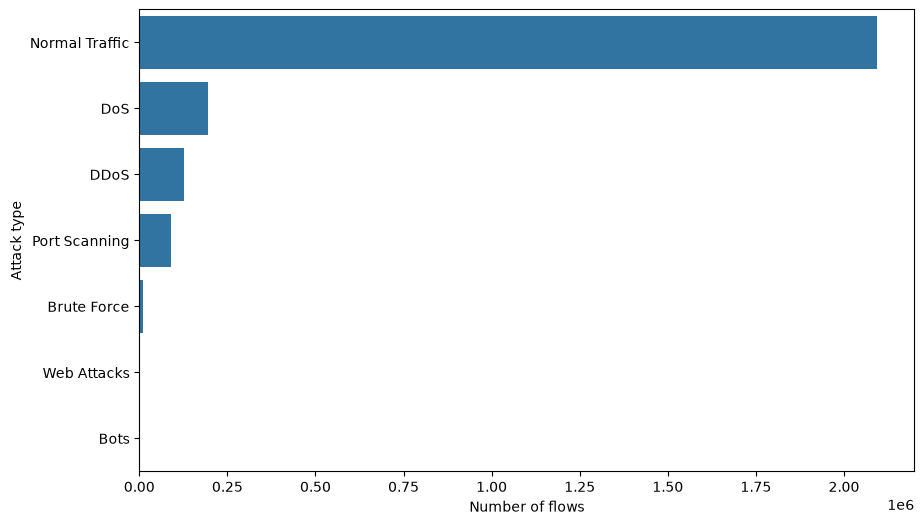

In [10]:
plt.figure(figsize=(10,6))
counts = df["Attack Type"].value_counts()
sns.barplot(x=counts.values,y=counts.index)
plt.xlabel("Number of flows")
plt.ylabel("Attack type")
plt.show()

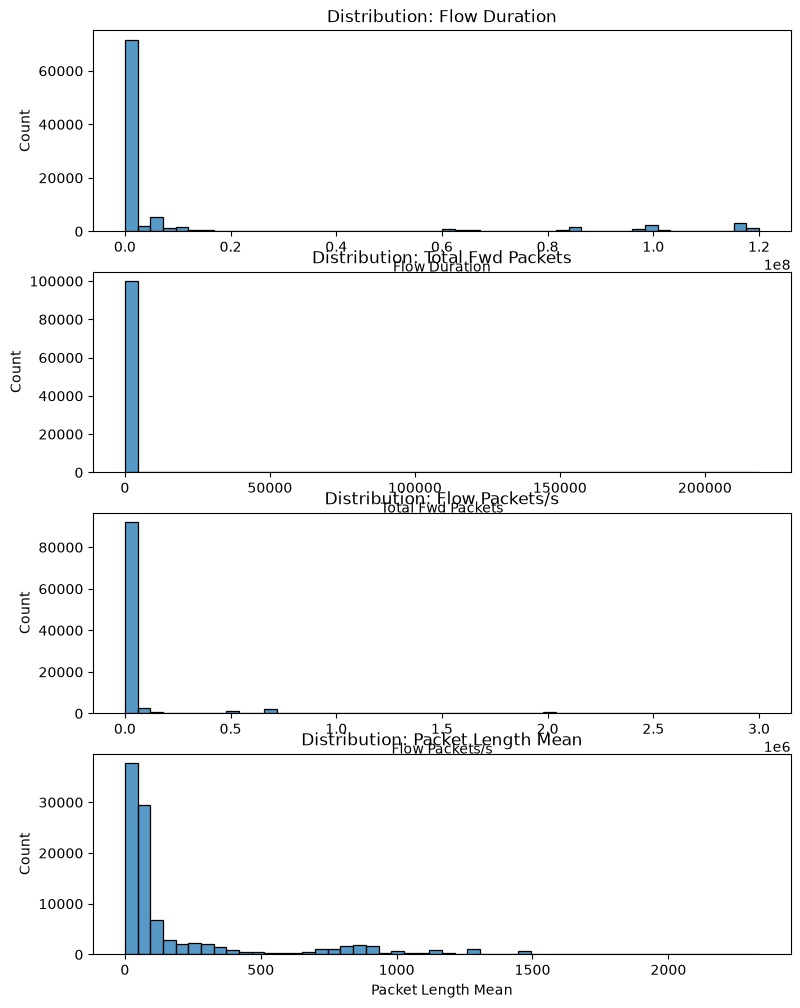

In [11]:
features = [
    "Flow Duration",
    "Total Fwd Packets",
    "Flow Packets/s",
    "Packet Length Mean",
]

available = [c for c in features if c in sample.columns]
fig, axes = plt.subplots(len(available), 1, figsize=(9, 3 * len(available)))
axes = np.atleast_1d(axes)

for ax, feature in zip(axes, available):
    values = pd.to_numeric(sample[feature], errors="coerce")
    values = values.replace([np.inf, -np.inf], np.nan).dropna()
    sns.histplot(values, bins=50, ax=ax)
    ax.set_title(f"Distribution: {feature}")


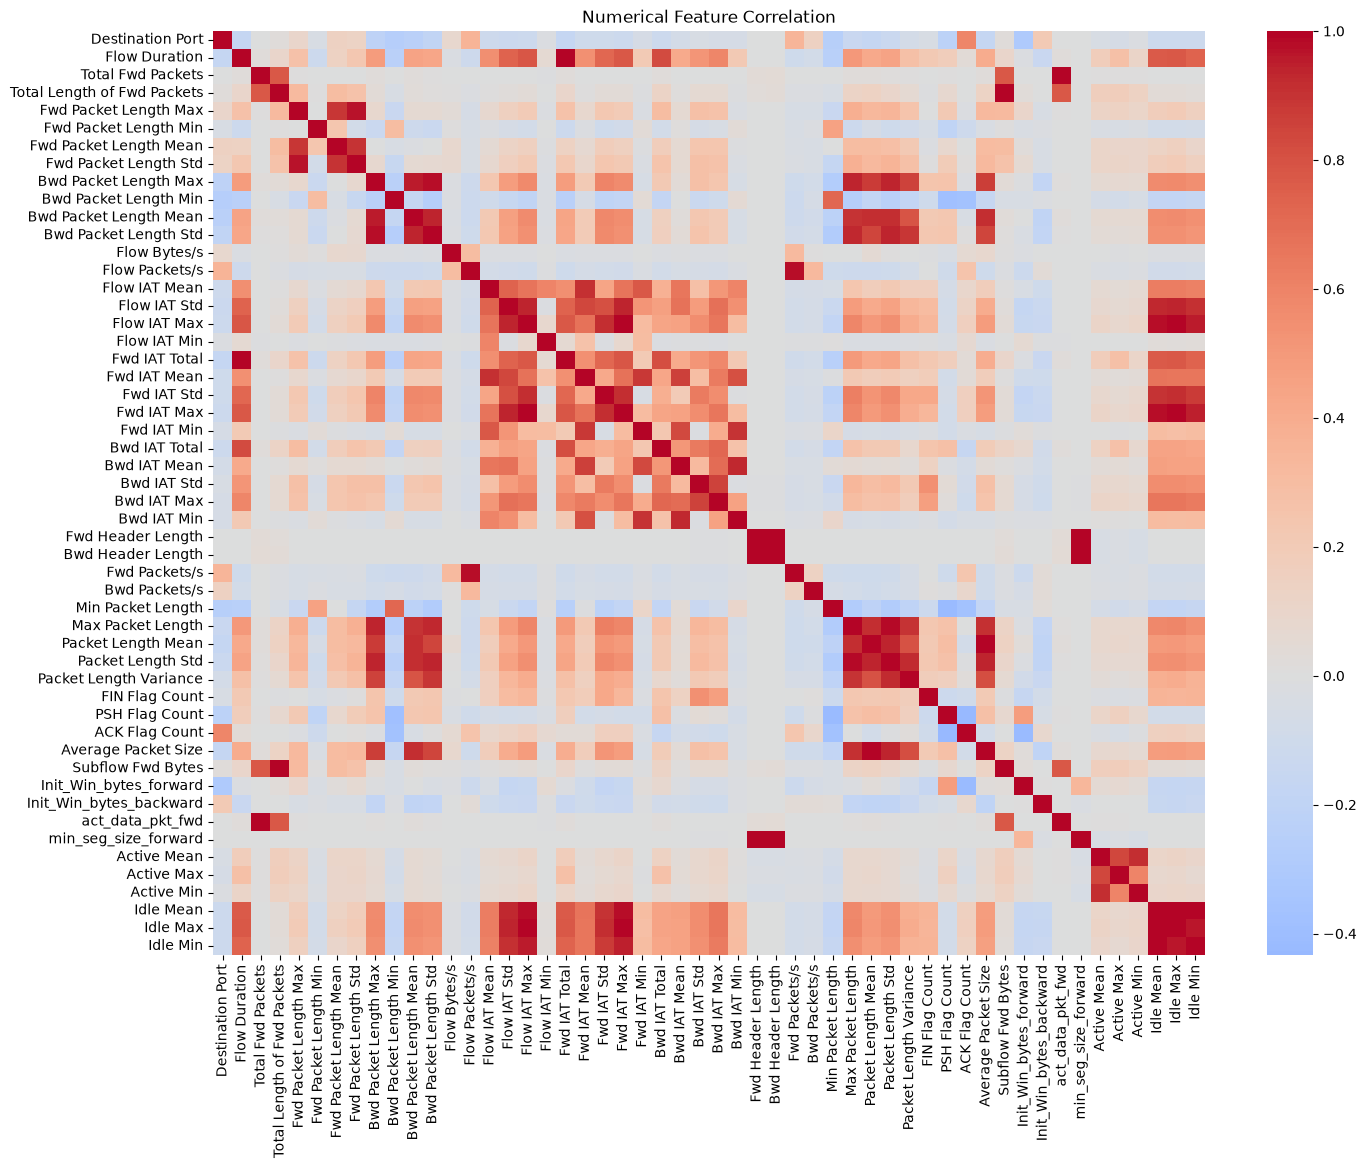

In [12]:
numeric = sample.select_dtypes(include=np.number)
numeric = numeric.replace([np.inf, -np.inf], np.nan)
correlation = numeric.corr()

plt.figure(figsize=(16, 12))
sns.heatmap(correlation, cmap="coolwarm", center=0)
plt.title("Numerical Feature Correlation")
plt.show()